# `tour.ipynb`

A detailed tour of running the mathematical model.

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import testis_model as tm

## Running the Gillespie model.

Set model parameters.

In [69]:
n_stem = 1000 # number of stem cells
n_clones = 10 # number of clones
r_event = 36  # rate of cell event
p_diff = 0.1  # probability that event is a differentiation 
q_div = 0.1   # probability that event is a symmetric division
r_decay = 6   # rate of sperm decay
sperm_per_diff = 1262 # number of sperm per differentiation

Set initial frequency and define the model.

In [70]:
rng = np.random.default_rng(1)

# Sample initial frequency from a uniform distribution.
init_freq = tm.gillespie.sample_ic(n_stem, n_clones, rng = rng)
print(f'The initial clone sizes will be {init_freq}.')

hmm = tm.gillespie.AdvancedTestisModel(
    n_stem, n_clones, r_event, p_diff, q_div, r_decay, sperm_per_diff, init_freq
)

The initial clone sizes will be [ 35 109 105 220  39 242  71 124   2  53].


Simulate and print model results.

In [71]:
# Sample three replicates at t = 1, 2, ..., 16.
record_times = np.repeat(np.arange(1, 16), 3)

# Assume 300 sperm sampled in each replicate.
n_sperm = 300

samples, records, means = hmm.simulate_gillespie(record_times, n_sperm = n_sperm, rng = rng)

# Order clones by size
tm.data_processing.sort_results(samples)
samples.head()

,time,n_sperm,obs_result,hid_result,full_result,replicate
0,1.0,300,"(70, 66, 39, 28, 26, 23, 22, 20, 6, 0)","(222, 212, 140, 85, 84, 112, 52, 69, 24, 0)","(2084403, 2049531, 1037757, 878890, 745228, 82...",1
1,1.0,300,"(65, 66, 43, 30, 24, 33, 18, 18, 3, 0)","(222, 212, 140, 85, 84, 112, 52, 69, 24, 0)","(2083991, 2051671, 1037574, 878702, 745091, 82...",2
2,1.0,300,"(78, 69, 38, 28, 19, 22, 17, 20, 9, 0)","(222, 212, 140, 85, 84, 112, 52, 69, 24, 0)","(2083957, 2051638, 1037559, 878680, 745081, 82...",3
3,2.0,300,"(64, 47, 37, 26, 57, 13, 20, 26, 10, 0)","(197, 172, 132, 98, 160, 51, 69, 73, 48, 0)","(1790641, 1586875, 1200489, 807152, 1534064, 6...",1
4,2.0,300,"(47, 50, 42, 32, 54, 25, 18, 23, 9, 0)","(197, 172, 132, 98, 160, 51, 69, 73, 48, 0)","(1790622, 1586849, 1200473, 807142, 1534040, 6...",2


Muller plots of the simulated data

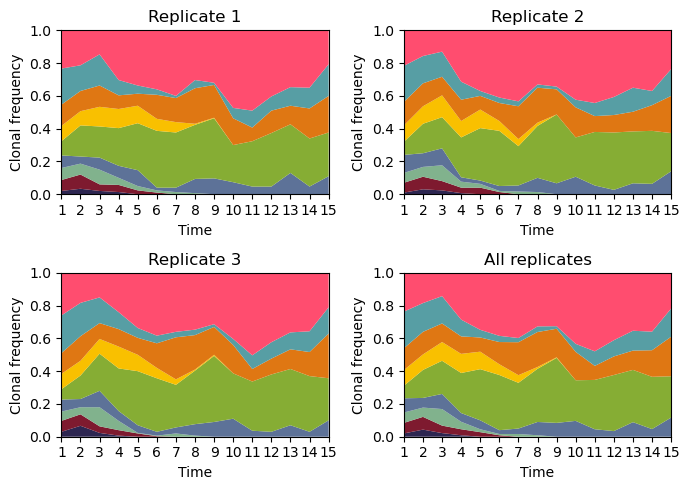

In [72]:
fig, ax = plt.subplots(2, 2, figsize = (7, 5))

tm.visualize.plot(samples, ax = ax[0, 0], replicate = 1)
ax[0, 0].set_title('Replicate 1')

tm.visualize.plot(samples, ax = ax[0, 1], replicate = 2)
ax[0, 1].set_title('Replicate 2')

tm.visualize.plot(samples, ax = ax[1, 0], replicate = 3)
ax[1, 0].set_title('Replicate 3')

tm.visualize.plot(samples, ax = ax[1, 1])
ax[1, 1].set_title('All replicates')

plt.tight_layout()

## Inference

We will now single out the red clone in the simulated data above and estimate its drift rate.

Note that the true effective drift rate is `r_event * (p_diff + q_div) = 7.2`.

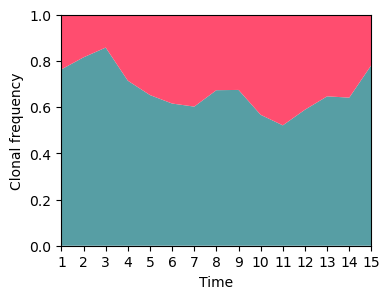

In [73]:
# Isolate the first clone, combining the rest together.
clone_samples = tm.data_processing.collapse(samples, 0)

fig, ax = plt.subplots(figsize = (4, 3))
tm.visualize.plot(clone_samples, ax = ax)

Define the likelihood model.

In [74]:
lm = tm.likelihood.LikelihoodModel(n_stem)

Compute the log-likelihood of the observed clonal data given a drift rate and initial clone frequency.

In [75]:
r_guess = 7.2
if_guess = 0.7

likelihood = lm.likelihood(clone_samples, 7.2, 0.3)
print(f'The log-likelihood of the given clone data given drift rate {r_guess} and initial frequency {if_guess} is {likelihood:.4f}.')

The log-likelihood of the given clone data given drift rate 7.2 and initial frequency 0.7 is -183.7592.


Compute the maximum likelihood estimator for the data.

In [83]:
statistic = 2 # test statistic for log likelihood ratio.
r_opt, if_opt, l_max, lower, upper = lm.max_likelihood(clone_samples, statistic = statistic)
print(f'The drift rate and initial frequency that maximize the likelihood are {r_opt:.4f} and {if_opt:.4f}, respectively. The log-likelihood is {l_max:.4f}.')
print(f'The lower and upper bounds for the drift rate confidence interval are [{lower:.4f}, {upper:.4f}].')

The drift rate and initial frequency that maximize the likelihood are 12.8682 and 0.2347, respectively. The log-likelihood is -176.9559.
The lower and upper bounds for the drift rate confidence interval are [4.7323, 47.2473].


Compare to the likelihood that there is no drift.

In [84]:
if_null, l_null = lm.max_likelihood_null(clone_samples)
print(f'The max likelihood for the model with no drift is {l_null:.4f}, when the initial frequency is {if_null:.4f}.')
print(f'Because the max likelihood for the model with drift ({l_max:.4f}) is significantly larger than the likelihood without drift ({l_null:.4f}), we conclude that there is positive drift.')

The max likelihood for the model with no drift is -530.4062, when the initial frequency is 0.3232.
Because the max likelihood for the model with drift (-176.9559) is significantly larger than the likelihood without drift (-530.4062), we conclude that there is positive drift.


## Application to experimental data

Now, we will measure the rate of drift of a clone in the experimental data.

In [131]:
import importlib
importlib.reload(tm.data_processing)

<module 'testis_model.data_processing' from '/Users/connor/Documents/github/sperm-data-analysis/testis_model/data_processing.py'>

In [132]:
experiment = '10.28.2025_04.57_PM'
data_path = f'../experiments/{experiment}/final_data.csv'
all_data = pd.read_csv(data_path)

Re-format the data to be readily applied to the model.

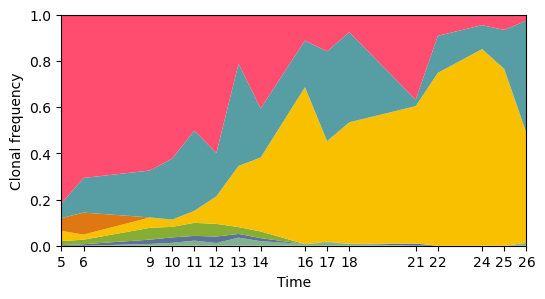

In [147]:
fish_data = all_data.query('fish == "fish5"').copy()
fish_table = tm.data_processing.convert_to_tuple_format(fish_data, n_sperm = 371)
fish_table['time'] = fish_table['time'].map(tm.data_processing.sample_map)

fig, ax = plt.subplots(figsize = (6, 3))
tm.visualize.plot(fish_table, ax = ax)

Isolate the first clone.

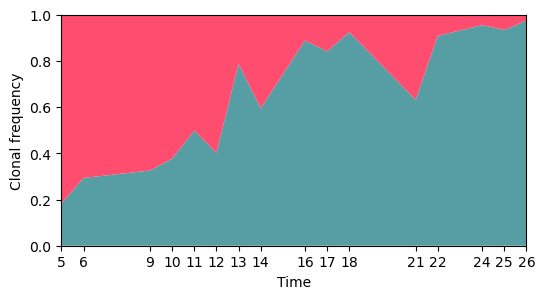

In [148]:
# Isolate the first clone, combining the rest together.
clone_samples = tm.data_processing.collapse(fish_table, 0)

fig, ax = plt.subplots(figsize = (6, 3))
tm.visualize.plot(clone_samples, ax = ax)

Define the likelihood model.

In [149]:
lm = tm.likelihood.LikelihoodModel(n_stem)

Compute the maximum likelihood estimator for the data.

In [150]:
statistic = 2 # test statistic for log likelihood ratio.
r_opt, if_opt, l_max, lower, upper = lm.max_likelihood(clone_samples, statistic = statistic)
print(f'The drift rate and initial frequency that maximize the likelihood are {r_opt:.4f} and {if_opt:.4f}, respectively. The log-likelihood is {l_max:.4f}.')
print(f'The lower and upper bounds for the drift rate confidence interval are [{lower:.4f}, {upper:.4f}].')

The drift rate and initial frequency that maximize the likelihood are 30.1485 and 0.5806, respectively. The log-likelihood is -183.2028.
The lower and upper bounds for the drift rate confidence interval are [13.3854, 75.9470].


The estimated drift rate of 30 is somewhat large, which makes sense given the large fluctuations that are seen.